# Prosit 3 — Stats OS : Clefs de Performance
## Analyse des performances des serveurs OPTIMAL (semaine du 9 au 15 juillet 2024)

**Mode d'emploi** : exécute les cellules dans l'ordre (menu *Run All*). Les passages **[À COMPLÉTER : …]** sont à remplir avec les valeurs affichées par le code juste au-dessus.

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 14          # texte plus gros, lisible au tableau
os.makedirs("figures", exist_ok=True)   # dossier où l'on enregistre les images

## 0. Chargement et contrôle des données

In [3]:
df = pd.read_csv("server_usage_data.csv")

print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print("Nombre de doublons :", df.duplicated().sum())

df["Time"] = pd.to_datetime(df["Time"])   # texte -> vraies dates
df = df.set_index("Time")                 # la date devient l'index

print("Début :", df.index.min())
print("Fin :", df.index.max())
df.info()

Valeurs manquantes par colonne :
Time             0
CPU_Usage        0
Memory_Usage     0
Network_Usage    0
Temperature      0
dtype: int64
Nombre de doublons : 0
Début : 2024-07-09 00:00:00
Fin : 2024-07-15 23:59:00
<class 'pandas.DataFrame'>
DatetimeIndex: 10080 entries, 2024-07-09 00:00:00 to 2024-07-15 23:59:00
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CPU_Usage      10080 non-null  float64
 1   Memory_Usage   10080 non-null  float64
 2   Network_Usage  10080 non-null  float64
 3   Temperature    10080 non-null  float64
dtypes: float64(4)
memory usage: 393.8 KB


In [4]:
# Listes réutilisées par tous les graphiques (même ordre partout)
colonnes = ["CPU_Usage", "Memory_Usage", "Network_Usage", "Temperature"]
libelles = ["CPU (%)", "Mémoire (Go)", "Réseau (Mbps)", "Température (°C)"]
couleurs = ["tab:blue", "tab:green", "tab:purple", "tab:brown"]

## 1. Statistiques descriptives

In [5]:
stats = df.describe()
stats.loc["IQR"] = stats.loc["75%"] - stats.loc["25%"]
stats.loc["Asymétrie"] = df.skew()
stats.loc["CV (%)"] = stats.loc["std"] / stats.loc["mean"] * 100
print(stats.round(2))

           CPU_Usage  Memory_Usage  Network_Usage  Temperature
count       10080.00      10080.00       10080.00     10080.00
mean           41.41          7.20         115.01        41.37
std            20.59          3.22          53.87         6.51
min            10.00          2.00          25.00        27.80
25%            25.63          4.79          74.55        36.24
50%            39.18          7.14         108.46        40.81
75%            55.39          9.04         159.78        46.80
max           100.00         16.00         200.00        57.86
IQR            29.76          4.25          85.23        10.56
Asymétrie       0.58          0.41           0.08         0.07
CV (%)         49.73         44.69          46.84        15.75


Les données couvrent une semaine complète (du 09/07/2024 00:00 au 15/07/2024 23:59), avec une mesure par minute, soit 10 080 observations par métrique. Aucune valeur manquante ni aucun doublon n'a été détecté.

| Indicateur | CPU (%) | Mémoire (Go) | Réseau (Mbps) | Température (°C) |
|---|---|---|---|---|
| Moyenne | 41,41 | 7,20 | 115,01 | 41,37 |
| Médiane | 39,18 | 7,14 | 108,46 | 40,81 |
| Écart-type | 20,59 | 3,22 | 53,87 | 6,51 |
| Min | 10,00 | 2,00 | 25,00 | 27,80 |
| Q1 | 25,63 | 4,79 | 74,55 | 36,24 |
| Q3 | 55,39 | 9,04 | 159,78 | 46,80 |
| Max | 100,00 | 16,00 | 200,00 | 57,86 |
| IQR | 29,76 | 4,25 | 85,23 | 10,56 |
| Asymétrie | 0,58 | 0,41 | 0,08 | 0,07 |
| Coefficient de variation | 50 % | 45 % | 47 % | 16 % |

*Coefficient de variation (CV) = écart-type / moyenne : il mesure la dispersion relative et permet de comparer des métriques d'unités différentes.*

**CPU** : l'utilisation moyenne (41,4 %) est légèrement supérieure à la médiane (39,2 %). L'asymétrie positive (0,58), la plus forte des quatre métriques, indique une traîne vers les valeurs élevées : quelques périodes de forte charge tirent la moyenne vers le haut. Le maximum de 100 % montre que le processeur atteint ponctuellement la saturation. Avec un CV de 50 %, c'est la métrique la plus irrégulière.

**Mémoire** : moyenne (7,20 Go) et médiane (7,14 Go) sont très proches, mais l'asymétrie reste positive (0,41) et la dispersion forte (CV de 45 %). La moitié centrale des mesures se situe entre 4,8 et 9,0 Go. Le maximum de 16 Go est une valeur ronde, qui correspond aux plateaux visibles sur les courbes : il suggère que la mémoire atteint sa capacité maximale lors des pics d'activité.

**Réseau** : la distribution est quasi symétrique (asymétrie de 0,08), mais très étalée (CV de 47 %, IQR de 85 Mbps). Le trafic varie fortement entre 25 et 200 Mbps. Comme pour la mémoire, le maximum rond de 200 Mbps suggère un plafond, probablement la limite de bande passante du lien.

**Température** : c'est la métrique la plus stable (CV de 16 %), avec une distribution symétrique (asymétrie de 0,07) et une moyenne proche de la médiane (41,4 °C contre 40,8 °C). Elle varie entre 27,8 et 57,9 °C. Cette stabilité s'explique par l'inertie thermique : un composant met du temps à chauffer et à refroidir, ce qui lisse les variations brutales de charge.

**Synthèse** : le CPU, la mémoire et le réseau sont très irréguliers et atteignent ponctuellement leur plafond (100 %, 16 Go, 200 Mbps) : le serveur connaît des épisodes de saturation. Les distributions du CPU et de la mémoire étant asymétriques, la **médiane** est plus représentative que la moyenne pour décrire leur niveau habituel.

> **À dire au tableau** : « Trois métriques sur quatre sont très irrégulières et touchent leur plafond : le serveur sature par moments. La question suivante, c'est : quand ? »

## 2. Évolution des métriques sur la semaine

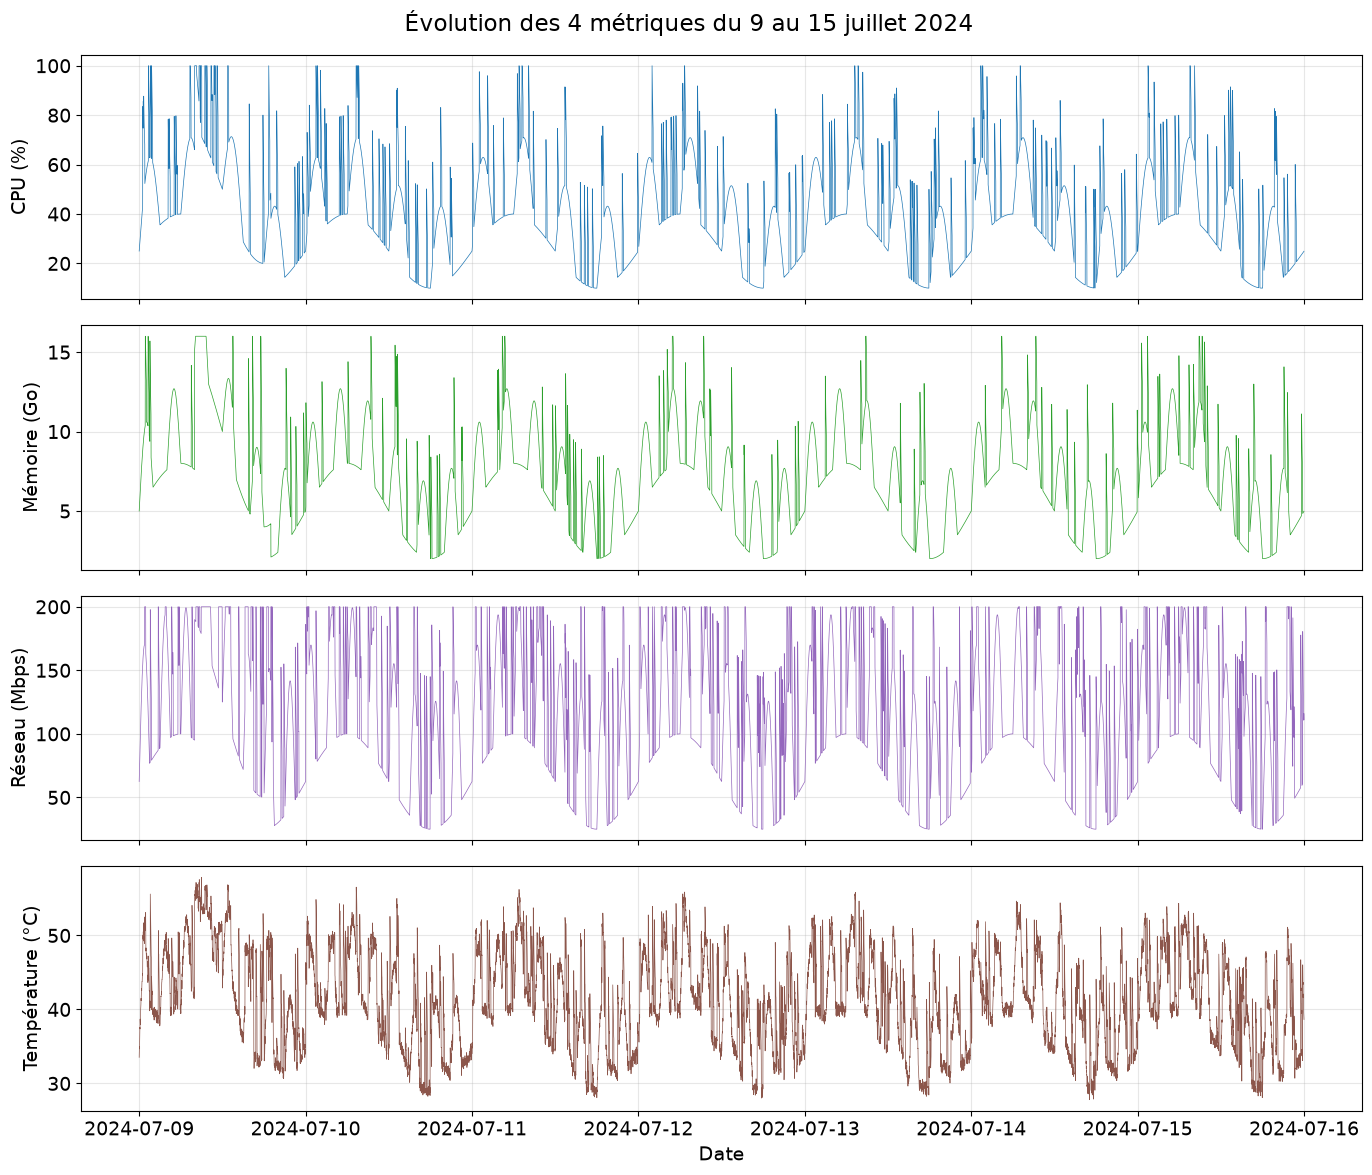

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

for i in range(4):
    axes[i].plot(df.index, df[colonnes[i]], color=couleurs[i], linewidth=0.5)
    axes[i].set_ylabel(libelles[i])
    axes[i].grid(alpha=0.3)

axes[3].set_xlabel("Date")
fig.suptitle("Évolution des 4 métriques du 9 au 15 juillet 2024")
plt.tight_layout()
plt.savefig("figures/02_courbes_semaine.png", dpi=150, bbox_inches="tight")
plt.show()

Sur l'ensemble de la semaine, les quatre métriques présentent un motif régulier. Les pics de CPU, de mémoire et de réseau surviennent au même moment, ce qui indique que les trois ressources sont solicitées au même moment. Les plateaux plats à 100 % (CPU), 16 Go (mémoire) et 200 Mbps (réseau) confirment les épisodes de saturation repérés dans les statistiques descriptives.

## 3. Zoom sur une journée : le 9 juillet 2024

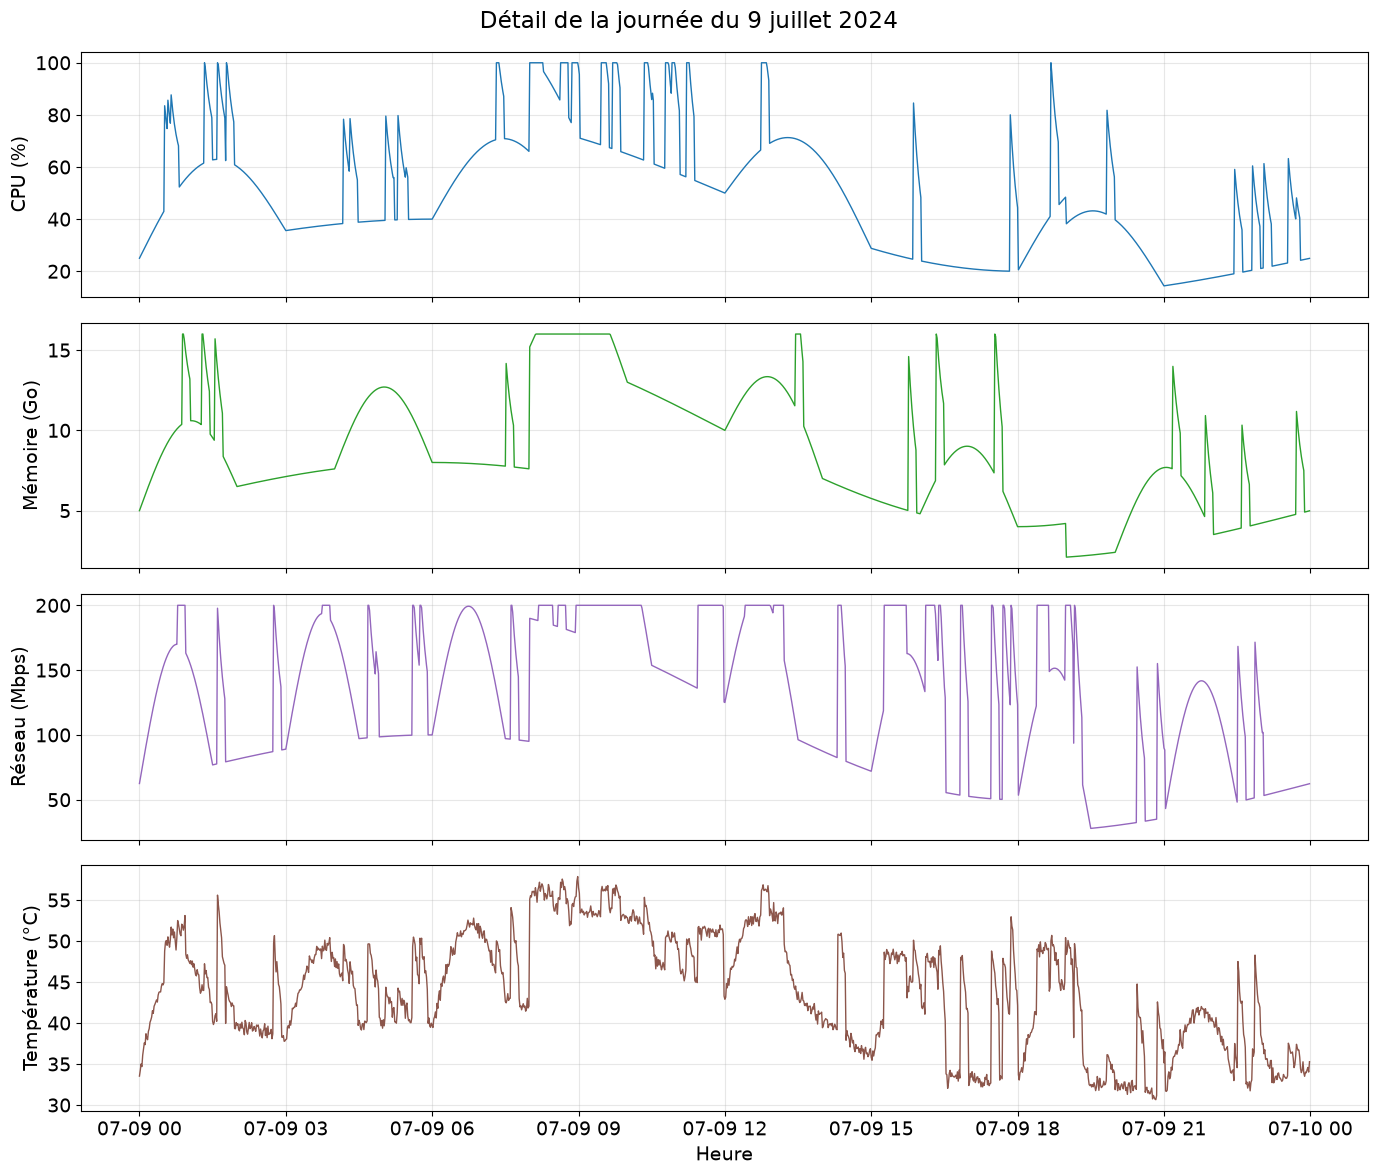

In [7]:
jour = df.loc["2024-07-09"]   # toutes les mesures de cette date

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

for i in range(4):
    axes[i].plot(jour.index, jour[colonnes[i]], color=couleurs[i], linewidth=1)
    axes[i].set_ylabel(libelles[i])
    axes[i].grid(alpha=0.3)

axes[3].set_xlabel("Heure")
fig.suptitle("Détail de la journée du 9 juillet 2024")
plt.tight_layout()
plt.savefig("figures/03_zoom_journee.png", dpi=150, bbox_inches="tight")
plt.show()

Sur cette journée type, la charge est élevée dès la nuit et jusqu’en début d’après-midi, puis diminue nettement à partir de 14h. La période la plus intense se situe entre 7h et 10h, avec un CPU qui atteint 100 %, une mémoire à 16 Go et un réseau à 200 Mbps de façon simultanée. La température suit la charge avec un léger retard, ce qui illustre l'inertie thermique.

## 4. Distribution des valeurs (histogrammes)

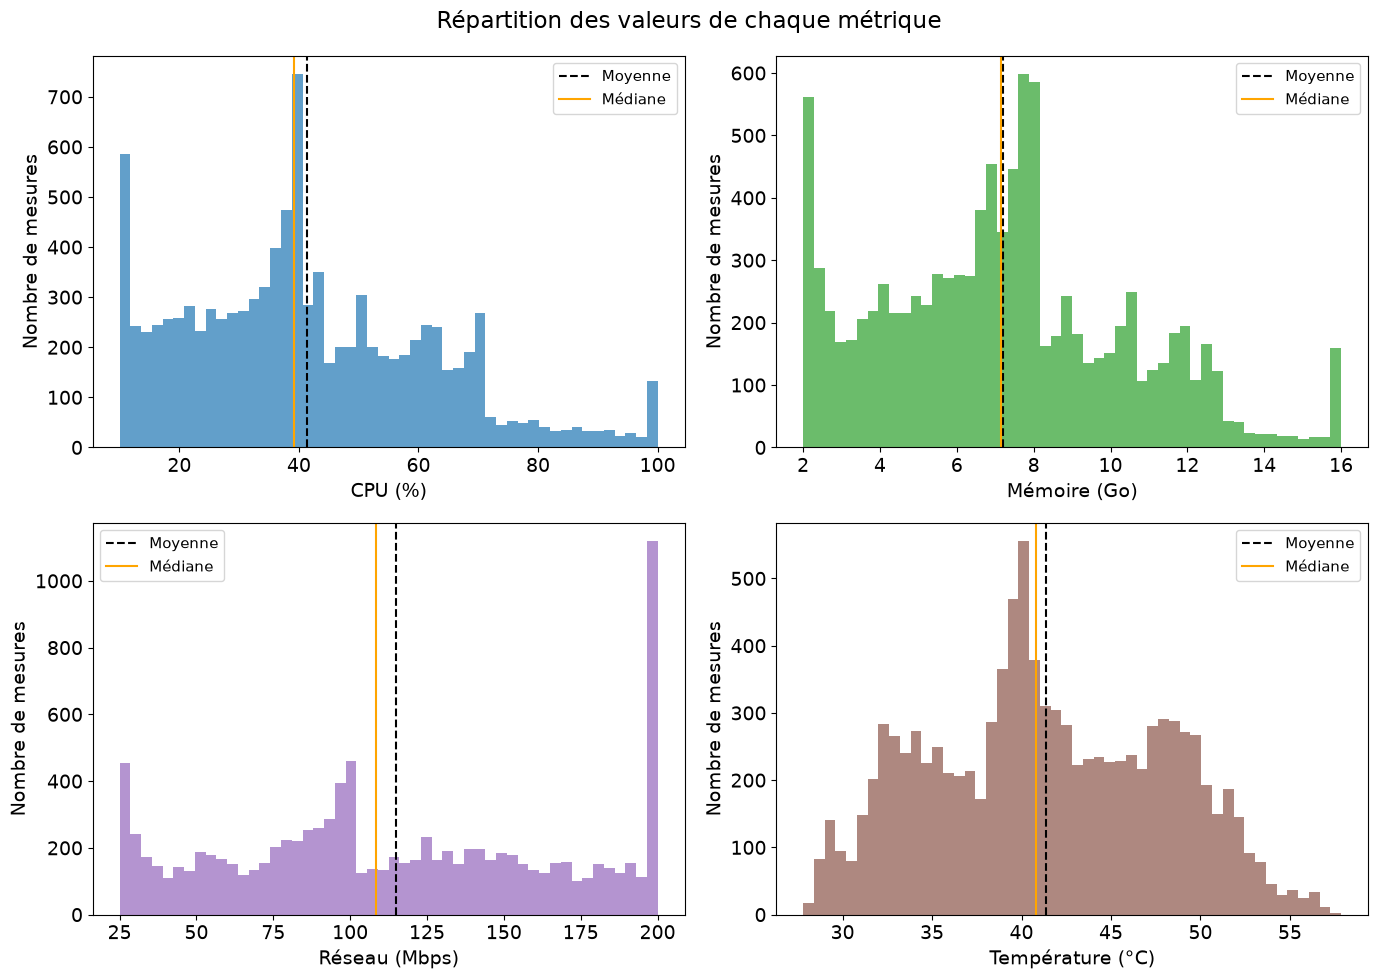

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()   # transforme la grille 2x2 en liste de 4 graphiques

for i in range(4):
    serie = df[colonnes[i]]
    axes[i].hist(serie, bins=50, color=couleurs[i], alpha=0.7)
    axes[i].axvline(serie.mean(), color="black", linestyle="--", label="Moyenne")
    axes[i].axvline(serie.median(), color="orange", linestyle="-", label="Médiane")
    axes[i].set_xlabel(libelles[i])
    axes[i].set_ylabel("Nombre de mesures")
    axes[i].legend(fontsize=11)

fig.suptitle("Répartition des valeurs de chaque métrique")
plt.tight_layout()
plt.savefig("figures/04_histogrammes.png", dpi=150, bbox_inches="tight")
plt.show()

Les histogrammes confirment les asymétries mesurées : pour le CPU et la mémoire, la moyenne (pointillés) est décalée à droite de la médiane, à cause des valeurs élevées. On observe aussi une barre isolée à droite à 100 % pour le CPU, à 16 Go pour la mémoire et à 200 Mbps pour le réseau : ce sont les mesures « bloquées » au plafond pendant les saturations. Le réseau présente deux bosses, et la température une forme proche d'une cloche.

Ces formes sont importantes pour la suite : le z-score suppose une distribution en cloche, ce qui n'est pas le cas du CPU, de la mémoire ni du réseau.

## 5. Dispersion et valeurs extrêmes (boîtes à moustaches)

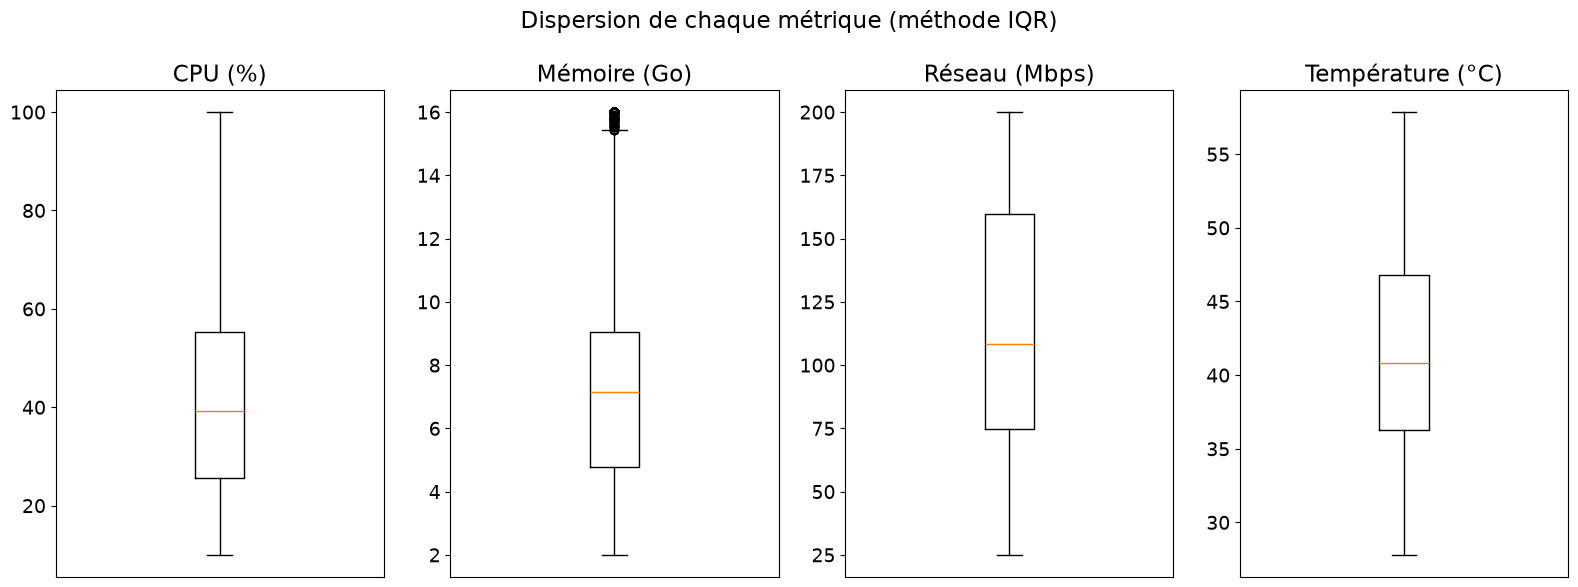

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 6))

for i in range(4):
    axes[i].boxplot(df[colonnes[i]])
    axes[i].set_title(libelles[i])
    axes[i].set_xticks([])   # pas de graduation inutile sous la boîte

fig.suptitle("Dispersion de chaque métrique (méthode IQR)")
plt.tight_layout()
plt.savefig("figures/05_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Chaque boîte représente la moitié centrale des mesures (de Q1 à Q3), avec la médiane en trait orange ; les moustaches s'arrêtent aux bornes de Tukey (Q1 − 1,5 × IQR et Q3 + 1,5 × IQR) ou à la valeur la plus extrême si elle est plus proche.

Seule la **mémoire** présente des points isolés au-dessus de la moustache : sa borne haute vaut 9,04 + 1,5 × 4,25 ≈ 15,4 Go, et les mesures à 16 Go la dépassent. Pour le CPU, la borne haute (≈ 100,0 %) est atteinte mais pas dépassée ; pour le réseau (≈ 287 Mbps) et la température (≈ 62,6 °C), elle est même au-delà du maximum observé.

## 6. Profil horaire : à quelle heure le serveur est-il chargé ?

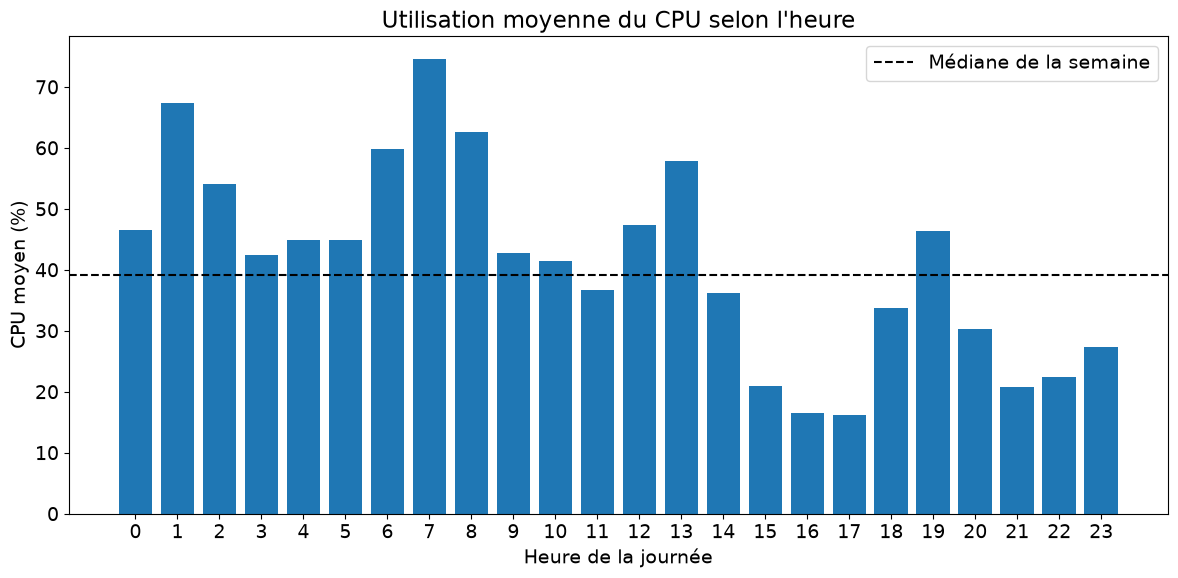

CPU moyen par heure :
Time
0     46.5
1     67.3
2     54.1
3     42.4
4     44.8
5     44.9
6     59.9
7     74.6
8     62.7
9     42.8
10    41.4
11    36.7
12    47.4
13    57.8
14    36.2
15    21.0
16    16.5
17    16.2
18    33.6
19    46.4
20    30.3
21    20.8
22    22.4
23    27.3
Name: CPU_Usage, dtype: float64
Heures au-dessus de la médiane :
Time
0     46.5
1     67.3
2     54.1
3     42.4
4     44.8
5     44.9
6     59.9
7     74.6
8     62.7
9     42.8
10    41.4
12    47.4
13    57.8
19    46.4
Name: CPU_Usage, dtype: float64


In [10]:
# Moyenne du CPU pour chaque heure de la journée (0 à 23), sur les 7 jours
cpu_par_heure = df.groupby(df.index.hour)["CPU_Usage"].mean()
mediane_cpu = df["CPU_Usage"].median()

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(cpu_par_heure.index, cpu_par_heure.values, color="tab:blue")
ax.axhline(mediane_cpu, color="black", linestyle="--", label="Médiane de la semaine")
ax.set_xticks(range(24))
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("CPU moyen (%)")
ax.set_title("Utilisation moyenne du CPU selon l'heure")
ax.legend()
plt.tight_layout()
plt.savefig("figures/06_cpu_par_heure.png", dpi=150, bbox_inches="tight")
plt.show()

print("CPU moyen par heure :")
print(cpu_par_heure.round(1))
print("Heures au-dessus de la médiane :")
print(cpu_par_heure[cpu_par_heure > mediane_cpu].round(1))

En moyenne sur la semaine, le CPU dépasse son niveau habituel (médiane de 39,2 %) entre minuit et 13h, avec un maximum de 74.6 % vers 7h. À l'inverse, les heures les plus calmes se situent entre 14h et 23h, avec un CPU moyen d'environ 27%.

La charge nocturne suggère que des tâches planifiées (sauvegardes, traitements par lots) s’exécutent la nuit et se cumulent avec l’activité du matin. Les étaler sur la plage creuse de 14 h à 23 h permettrait de lisser la charge.

## 7. Carte de chaleur : CPU moyen par jour et par heure

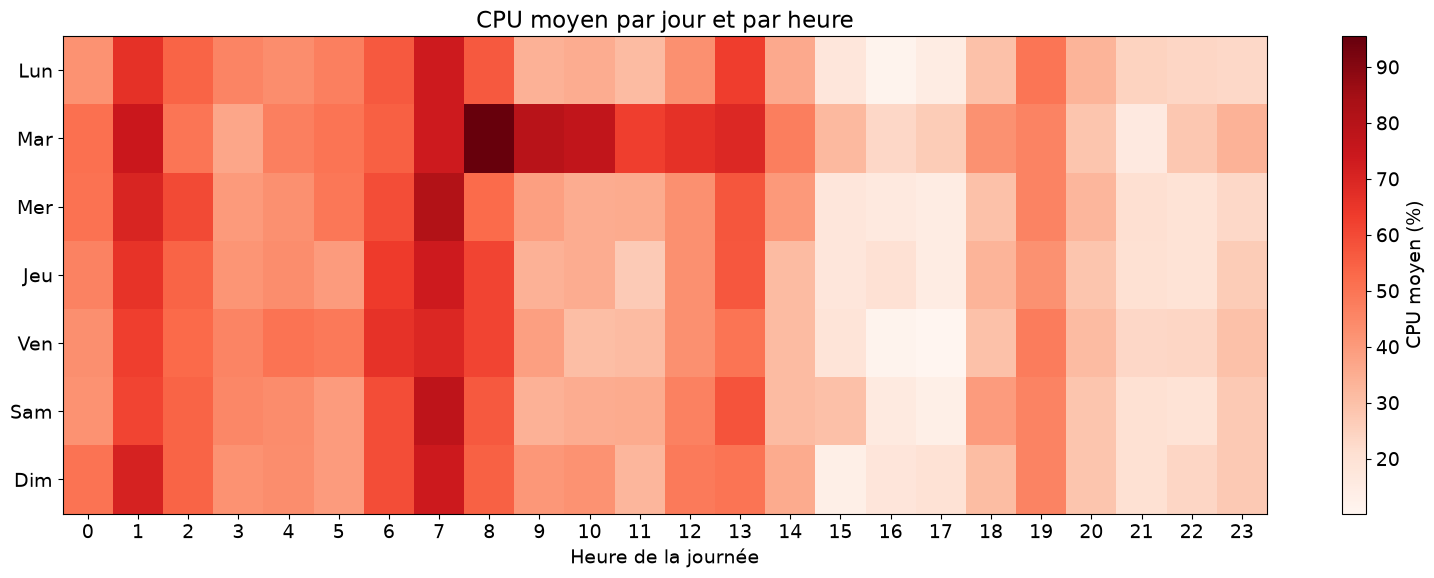

In [11]:
# Tableau croisé : une ligne par jour de la semaine, une colonne par heure
carte = pd.pivot_table(df, values="CPU_Usage",
                       index=df.index.dayofweek, columns=df.index.hour,
                       aggfunc="mean")

fig, ax = plt.subplots(figsize=(16, 6))
image = ax.imshow(carte, aspect="auto", cmap="Reds")
fig.colorbar(image, ax=ax, label="CPU moyen (%)")
ax.set_xticks(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"])
ax.set_xlabel("Heure de la journée")
ax.set_title("CPU moyen par jour et par heure")
plt.tight_layout()
plt.savefig("figures/07_carte_chaleur.png", dpi=150, bbox_inches="tight")
plt.show()

Plus la case est rouge, plus le CPU est chargé. La carte montre que les heures de pointe sont globalement les mêmes tous les jours. Même le weekend est très chargé, ce qui nuance l'idée d'une charge liée à l'activité des utilisateurs.

## 8. Détection d'anomalies et seuils de vigilance

Trois méthodes sont comparées sur chaque métrique :
- **z-score** : anormal si |x − moyenne| / écart-type > 3 ;
- **IQR (Tukey)** : anormal si x < Q1 − 1,5 × IQR ou x > Q3 + 1,5 × IQR ;
- **MAD** : anormal si |x − médiane| > 3 × 1,4826 × MAD, où MAD = médiane des écarts absolus à la médiane.

On ajoute deux indicateurs opérationnels : le **95e percentile (P95)**, valeur dépassée seulement 5 % du temps, et le **temps passé au plafond** (en % de la semaine).

In [12]:
resultats = []

for col in colonnes:
    x = df[col]

    # z-score
    moyenne = x.mean()
    ecart_type = x.std(ddof=0)
    nb_z = ((x - moyenne).abs() / ecart_type > 3).sum()

    # IQR
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    borne_iqr_basse = q1 - 1.5 * iqr
    borne_iqr_haute = q3 + 1.5 * iqr
    nb_iqr = ((x < borne_iqr_basse) | (x > borne_iqr_haute)).sum()

    # MAD
    mediane = x.median()
    mad = (x - mediane).abs().median()
    nb_mad = ((x - mediane).abs() > 3 * 1.4826 * mad).sum()

    # Indicateurs opérationnels
    p95 = x.quantile(0.95)
    temps_au_max = (x >= x.max()).mean() * 100

    resultats.append({
        "Métrique": col,
        "Borne haute z": moyenne + 3 * ecart_type,
        "Anomalies z": nb_z,
        "Borne haute IQR": borne_iqr_haute,
        "Anomalies IQR": nb_iqr,
        "Borne haute MAD": mediane + 3 * 1.4826 * mad,
        "Anomalies MAD": nb_mad,
        "P95": p95,
        "% temps au max": temps_au_max,
    })

tableau_anomalies = pd.DataFrame(resultats).set_index("Métrique")
print(tableau_anomalies.round(2).to_string())

               Borne haute z  Anomalies z  Borne haute IQR  Anomalies IQR  Borne haute MAD  Anomalies MAD     P95  % temps au max
Métrique                                                                                                                         
CPU_Usage             103.18            0           100.03              0           104.20              0   78.57            1.15
Memory_Usage           16.85            0            15.42            175            16.88              0   12.66            1.41
Network_Usage         276.63            0           287.62              0           299.15              0  200.00            9.61
Temperature            60.91            0            62.64              0            64.34              0   51.81            0.01


### Comparaison des méthodes

| Métrique | Borne z | Anomalies z | Borne IQR | Anomalies IQR | Borne MAD | Anomalies MAD | P95 | % temps au max |
|---|---|---|---|---|---|---|---|---|
| CPU (%) | 103,2 | 0 | 100,0 | 0 | 104,2 | 0 | 78,6 | 1,15 % |
| Mémoire (Go) | 16,9 | 0 | 15,4 | 175 | 16,9 | 0 | 12,7 | 1,41 % |
| Réseau (Mbps) | 276,6 | 0 | 287,6 | 0 | 299,2 | 0 | 200,0 | 9,61 % |
| Température (°C) | 60,9 | 0 | 62,6 | 0 | 64,3 | 0 | 51,8 | — |

*Bornes hautes uniquement : les bornes basses sont toutes inférieures aux minimums observés et ne détectent rien.*

**Constat principal** : sur 40 320 mesures (4 métriques × 10 080), les méthodes statistiques ne détectent que 175 anomalies, toutes par l'IQR et toutes sur la mémoire. Ce n'est pas parce que le serveur se porte bien : c'est parce que le CPU, la mémoire et le réseau sont **plafonnés** par la capacité matérielle (100 %, 16 Go, 200 Mbps). Une valeur ne peut pas dépasser le maximum physique, donc elle ne peut pas « sortir » des bornes statistiques, qui se situent presque toutes au-dessus de ce maximum. La saturation est fréquente, donc statistiquement « normale », alors qu'elle pose un vrai problème de performance.

- Le **z-score** est le moins adapté : il suppose une distribution en cloche, ce qui n'est pas le cas ici, et sa moyenne et son écart-type sont eux-mêmes influencés par les pics. Il ne détecte rien.
- L'**IQR** est plus robuste et est la seule méthode à repérer quelque chose : 175 mesures de mémoire au-dessus de 15,4 Go, qui correspondent aux plateaux à 16 Go.
- La **MAD** est la plus robuste aux valeurs extrêmes, mais elle ne détecte aucune anomalie : ses bornes sont toutes au-delà du plafond physique (104,2 % pour le CPU, 16,9 Go pour la mémoire, 299,2 Mbps pour le réseau). Sa robustesse est un avantage face à des pics isolés, mais elle ne voit pas une saturation répétée.

### Seuils de vigilance proposés

Plutôt qu'un seuil d'anomalie statistique, on propose un **seuil de vigilance au 95e percentile** : une alerte se déclenche quand la métrique entre dans les 5 % de valeurs les plus hautes observées. On le complète par le **temps passé au plafond**, qui mesure directement la saturation.

| Métrique | Seuil de vigilance (P95) | Temps passé au plafond |
|---|---|---|
| CPU | 78,6 % | 1,15 % de la semaine (116 min, soit environ 2 h) |
| Mémoire | 12,7 Go | 1,41 % (142 min, soit environ 2 h 20) |
| Réseau | 200 Mbps (= plafond) | 9,61 % (969 min, soit environ 16 h) |
| Température | 51,8 °C | — |

Cas particulier du **réseau** : son P95 est égal au plafond de 200 Mbps, car le lien est saturé près de 10 % du temps. Le P95 ne peut donc pas servir de seuil d'alerte anticipée. Pour cette métrique, on retient le temps passé à 200 Mbps comme indicateur principal, ou un seuil plus bas, par exemple au 90e percentile. Le réseau est la ressource la plus saturée du serveur : environ 16 h par semaine au maximum.

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)

for i in range(4):
    x = df[colonnes[i]]
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    borne_iqr = q3 + 1.5 * (q3 - q1)
    seuil = x.quantile(0.95)
    alertes = x[x > seuil]   # mesures au-dessus du seuil de vigilance

    axes[i].plot(x.index, x, color=couleurs[i], linewidth=0.5)
    axes[i].scatter(alertes.index, alertes, color="red", s=4, label="Au-dessus du seuil")
    axes[i].axhline(seuil, color="red", linestyle="--", label="Seuil de vigilance (P95)")
    axes[i].axhline(borne_iqr, color="gray", linestyle=":", label="Borne IQR")
    axes[i].set_ylabel(libelles[i])
    axes[i].grid(alpha=0.3)

axes[0].legend(loc="upper right", fontsize=10)
axes[3].set_xlabel("Date")
fig.suptitle("Seuils de vigilance (P95) et borne IQR")
plt.tight_layout()
plt.savefig("figures/08_seuils_vigilance.png", dpi=150, bbox_inches="tight")
plt.show()

Les points rouges marquent les mesures qui dépassent le seuil de vigilance. Pour le **CPU**, ils se concentrent la nuit et au début de matinée : plus de la moitié des 504 dépassements ont lieu à 1 h, 7 h et 8 h. Pour la **mémoire**, ils se situent surtout à 8-9 h (environ 40 %) et à 4-5 h. Pour la **température**, ils sont groupés entre 6 h et 9 h (plus de 60 % des dépassements). Le **réseau**, lui, sature à 200 Mbps à de nombreuses heures de la journée (9 h, 12 h, 15 h, 6 h, minuit, 21 h…) : sa saturation n'est pas liée à un seul créneau.

La ligne grise (borne IQR) est au niveau du plafond pour le CPU et au-dessus des données pour le réseau et la température : elle ne permettrait pas de déclencher d'alerte, contrairement au P95. Seule la mémoire a une borne IQR (15,4 Go) en dessous de son plafond.

## 9. Corrélations entre métriques

               CPU_Usage  Memory_Usage  Network_Usage  Temperature
CPU_Usage           1.00          0.43           0.32         0.60
Memory_Usage        0.43          1.00           0.36         0.49
Network_Usage       0.32          0.36           1.00         0.94
Temperature         0.60          0.49           0.94         1.00


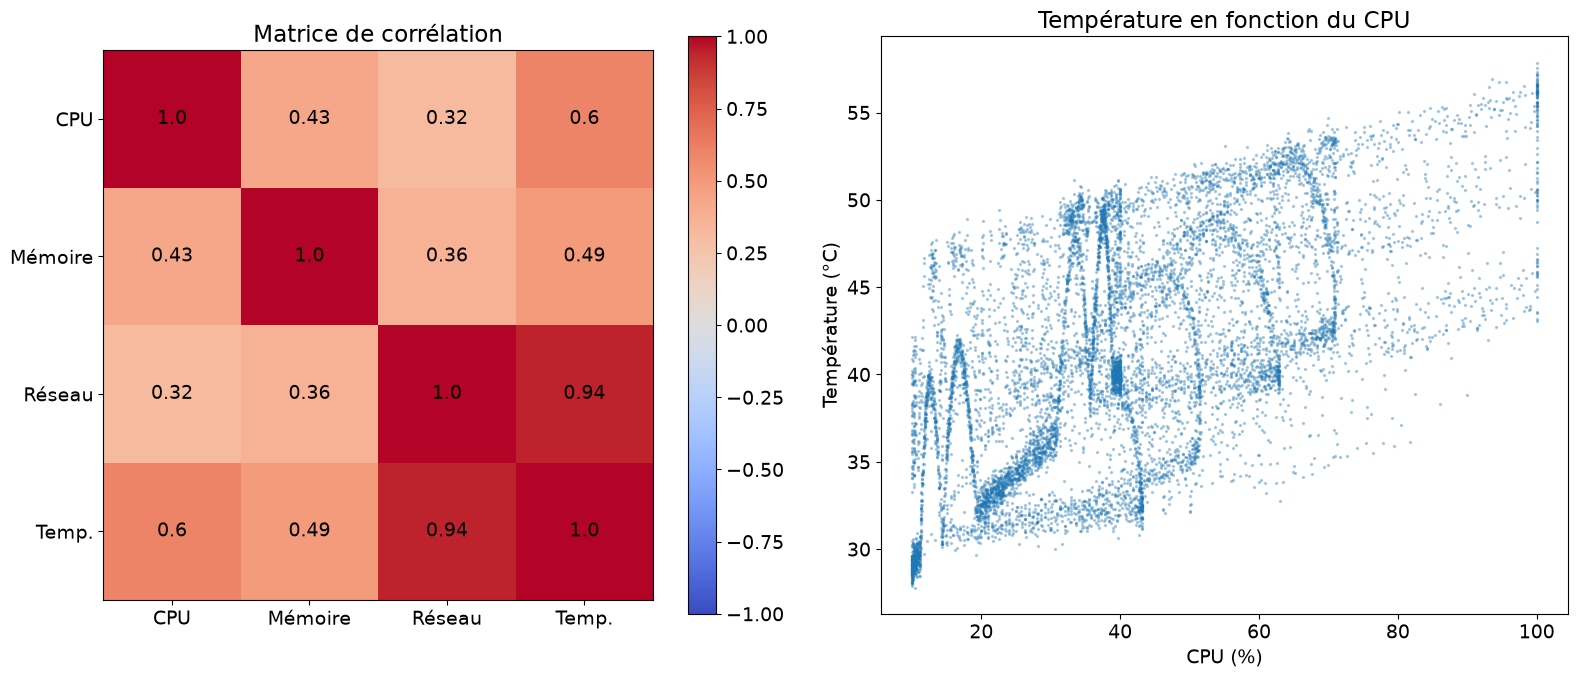

In [13]:
corr = df.corr()
print(corr.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Matrice de corrélation
image = axes[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(image, ax=axes[0])
axes[0].set_xticks(range(4))
axes[0].set_yticks(range(4))
axes[0].set_xticklabels(["CPU", "Mémoire", "Réseau", "Temp."])
axes[0].set_yticklabels(["CPU", "Mémoire", "Réseau", "Temp."])
for ligne in range(4):
    for col in range(4):
        axes[0].text(col, ligne, round(corr.iloc[ligne, col], 2),
                     ha="center", va="center")
axes[0].set_title("Matrice de corrélation")

# Nuage de points CPU / température
axes[1].scatter(df["CPU_Usage"], df["Temperature"], s=2, alpha=0.3)
axes[1].set_xlabel("CPU (%)")
axes[1].set_ylabel("Température (°C)")
axes[1].set_title("Température en fonction du CPU")

plt.tight_layout()
plt.savefig("figures/09_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

Le coefficient de corrélation r varie entre −1 et 1 : proche de 1, les deux métriques montent ensemble ; proche de 0, il n'y a pas de lien linéaire.

| | CPU | Mémoire | Réseau | Température |
|---|---|---|---|---|
| CPU | 1 | 0,43 | 0,32 | 0,60 |
| Mémoire | 0,43 | 1 | 0,36 | 0,49 |
| Réseau | 0,32 | 0,36 | 1 | **0,94** |
| Température | 0,60 | 0,49 | **0,94** | 1 |

Le lien le plus fort, et de loin, est entre le **réseau et la température (r = 0,94)** : quand le trafic augmente, la température augmente presque systématiquement. La température est aussi liée au CPU, mais plus modérément (r = 0,60). En revanche, le CPU, la mémoire et le réseau sont **faiblement liés entre eux** (r entre 0,32 et 0,43) : ils ne sont pas sollicités par les mêmes tâches au même moment, et doivent donc être surveillés séparément.

Le lien réseau / température est surprenant : on s'attendrait plutôt à ce que le CPU fasse chauffer le serveur. Deux hypothèses : les transferts de données sollicitent fortement la carte réseau et les disques, qui chauffent ; ou le capteur de température est placé près de l'équipement réseau. Attention : une corrélation ne prouve pas une causalité, et ce lien serait à vérifier avec l'équipe infrastructure.

## 10. Recommandations

1. **Augmenter la bande passante réseau (priorité).** Le lien est saturé à 200 Mbps pendant environ 16 h par semaine (9,6 % du temps), à de nombreuses heures de la journée : c'est la ressource la plus contrainte du serveur. Il faut augmenter le débit du lien ou étaler les gros transferts de données. Vu la corrélation de 0,94 avec la température, cela réduirait probablement aussi l'échauffement.
2. **Étaler les tâches planifiées.** Le CPU est chargé de minuit à 10 h, avec des pics à 1 h et 7 h qui reviennent tous les jours, week-end compris (parties 6 et 7). Les sauvegardes, traitements par lots et mises à jour doivent être répartis sur les plages creuses de **15 h-17 h** et **21 h-23 h**, au lieu de s'empiler la nuit et le matin.
3. **Mettre en place des alertes sur les seuils de vigilance (P95)** : 78,6 % pour le CPU, 12,7 Go pour la mémoire et 51,8 °C pour la température. Une alerte au franchissement permet d'agir avant la saturation (partie 8).
4. **Optimiser ou augmenter la mémoire.** La mémoire atteint 16 Go pendant environ 2 h 20 par semaine, et c'est la seule métrique où l'IQR détecte des anomalies (175 mesures). Il faut identifier les applications responsables des pics de 8-9 h et 4-5 h, et envisager d'ajouter de la RAM.
5. **Surveiller le temps passé en saturation CPU.** Le CPU est à 100 % pendant 1,15 % de la semaine (environ 2 h), concentré à 1 h, 7 h et 8 h. Si cette durée augmente, il faudra plus de capacité ou une meilleure répartition de la charge.
6. **Analyser la journée du 9 juillet.** Elle est nettement plus chargée que les autres (CPU moyen de 95 % à 8 h) : il faut en chercher la cause (déploiement, incident, pic d'activité exceptionnel).
7. **Utiliser la médiane et des méthodes robustes** (IQR, MAD, percentiles) plutôt que la moyenne et le z-score pour superviser ces métriques asymétriques et plafonnées.